In [5]:
!pip -q install selfcheckgpt datasets scikit-learn pandas matplotlib spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 30.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [6]:
from datasets import load_dataset

ds = load_dataset("potsawee/wiki_bio_gpt3_hallucination")
print(ds)
print(ds["evaluation"].column_names)
print("Rows:", len(ds["evaluation"]))

row = ds["evaluation"][0]
for key in [
    "gpt3_text",
    "gpt3_sentences",
    "annotation",
    "gpt3_text_samples",
]:
    value = row.get(key)
    print(key, type(value), len(value) if value is not None else None)

DatasetDict({
    evaluation: Dataset({
        features: ['gpt3_text', 'wiki_bio_text', 'gpt3_sentences', 'annotation', 'wiki_bio_test_idx', 'gpt3_text_samples'],
        num_rows: 238
    })
})
['gpt3_text', 'wiki_bio_text', 'gpt3_sentences', 'annotation', 'wiki_bio_test_idx', 'gpt3_text_samples']
Rows: 238
gpt3_text <class 'str'> 913
gpt3_sentences <class 'list'> 9
annotation <class 'list'> 9
gpt3_text_samples <class 'list'> 20


In [7]:
import torch
import spacy
from selfcheckgpt.modeling_selfcheck import SelfCheckNgram

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

scorer = SelfCheckNgram(n=1)

row = ds["evaluation"][0]
sentences = row["gpt3_sentences"]
samples = row["gpt3_text_samples"][:5]

scores = scorer.predict(
    sentences=sentences,
    passage=row["gpt3_text"],
    sampled_passages=samples,
)

print(scores)

Device: cuda
SelfCheck-1gram initialized
{'sent_level': {'avg_neg_logprob': [np.float64(4.557909518857286), np.float64(4.403209982951789), np.float64(4.519976171818104), np.float64(4.4355725685129945), np.float64(4.700472122087795), np.float64(4.671928822897819), np.float64(4.651470108329495), np.float64(4.7412318808107585), np.float64(4.725377103271128)], 'max_neg_logprob': [np.float64(7.051855622955894), np.float64(7.051855622955894), np.float64(7.051855622955894), np.float64(7.051855622955894), np.float64(7.051855622955894), np.float64(7.051855622955894), np.float64(7.051855622955894), np.float64(7.051855622955894), np.float64(7.051855622955894)]}, 'doc_level': {'avg_neg_logprob': np.float64(4.608321708421292), 'avg_max_neg_logprob': np.float64(7.051855622955894)}}


In [8]:
import torch
import spacy

from selfcheckgpt.modeling_selfcheck import SelfCheckNgram

# check whether GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# create the SelfCheckGPT scorer
scorer = SelfCheckNgram(n=1)

# select the first example from our dataset
row = ds["evaluation"][0]

# get its sentences and sample passages
sentences = row["gpt3_sentences"]
samples = row["gpt3_text_samples"][:5]

# calculate hallucination scores
scores = scorer.predict(
    sentences=sentences,
    passage=row["gpt3_text"],
    sampled_passages=samples
)

print("\nOriginal sentences:")
print(sentences)

print("\nNumber of sample passages:", len(samples))

print("\nSelfCheckGPT scores:")
print(scores)

Device: cuda
SelfCheck-1gram initialized

Original sentences:
['John Russell Reynolds (1820–1876) was an English lawyer, judge, and author.', 'He was born in London, the son of a barrister, and was educated at Eton College and Trinity College, Cambridge.', "He was called to the bar in 1845, and became a Queen's Counsel in 1859.", 'He was appointed a judge of the Court of Common Pleas in 1867, and was knighted in 1871.', 'Reynolds was a prolific author, writing on a wide range of topics.', 'He wrote several books on legal topics, including The Law of Libel and Slander (1863), The Law of Copyright (1865), and The Law of Patents for Inventions (1868).', 'He also wrote on a variety of other topics, including history, biography, and literature.', 'He was a frequent contributor to the Saturday Review, and wrote several books on Shakespeare, including The Mystery of William Shakespeare (1848) and The Authorship of Shakespeare (1875).', 'He also wrote a biography of the poet John Keats (1848).

In [9]:
import pandas as pd

sentence_scores = scores["sent_level"]["avg_neg_logprob"]

results = pd.DataFrame({
    "Sentence": sentences,
    "Hallucination_Score": sentence_scores
})

display(results)

,Sentence,Hallucination_Score
0,John Russell Reynolds (1820–1876) was an Engli...,4.557910
1,"He was born in London, the son of a barrister,...",4.403210
2,"He was called to the bar in 1845, and became a...",4.519976
3,He was appointed a judge of the Court of Commo...,4.435573
4,"Reynolds was a prolific author, writing on a w...",4.700472
5,"He wrote several books on legal topics, includ...",4.671929
6,"He also wrote on a variety of other topics, in...",4.651470
7,He was a frequent contributor to the Saturday ...,4.741232
8,He also wrote a biography of the poet John Kea...,4.725377


In [10]:
# display the original human annotations

print("Total sentences:", len(row["gpt3_sentences"]))
print("Total annotations:", len(row["annotation"]))

print("\nHuman annotations:")

for i, (sentence, label) in enumerate(
    zip(row["gpt3_sentences"], row["annotation"])
):
    print(f"\nSentence {i+1}: {sentence}")
    print("Human label:", label)

Total sentences: 9
Total annotations: 9

Human annotations:

Sentence 1: John Russell Reynolds (1820–1876) was an English lawyer, judge, and author.
Human label: major_inaccurate

Sentence 2: He was born in London, the son of a barrister, and was educated at Eton College and Trinity College, Cambridge.
Human label: major_inaccurate

Sentence 3: He was called to the bar in 1845, and became a Queen's Counsel in 1859.
Human label: major_inaccurate

Sentence 4: He was appointed a judge of the Court of Common Pleas in 1867, and was knighted in 1871.
Human label: major_inaccurate

Sentence 5: Reynolds was a prolific author, writing on a wide range of topics.
Human label: major_inaccurate

Sentence 6: He wrote several books on legal topics, including The Law of Libel and Slander (1863), The Law of Copyright (1865), and The Law of Patents for Inventions (1868).
Human label: major_inaccurate

Sentence 7: He also wrote on a variety of other topics, including history, biography, and literature.
H

In [11]:
from collections import Counter

label_counts = Counter()

for example in ds["evaluation"]:
    label_counts.update(example["annotation"])

print("Human annotation distribution:\n")

for label, count in label_counts.items():
    print(f"{label}: {count}")

print("\nTotal annotated sentences:", sum(label_counts.values()))

Human annotation distribution:

major_inaccurate: 761
minor_inaccurate: 631
accurate: 516

Total annotated sentences: 1908


In [12]:
import pandas as pd

# create a table containing every sentence and its human label
all_rows = []

for doc_id, example in enumerate(ds["evaluation"]):

    for sent_id, (sentence, label) in enumerate(
        zip(example["gpt3_sentences"], example["annotation"])
    ):

        # convert human labels into binary values
        binary_label = 0 if label == "accurate" else 1

        all_rows.append({
            "doc_id": doc_id,
            "sentence_id": sent_id,
            "sentence": sentence,
            "human_label": label,
            "actual": binary_label
        })

# create a DataFrame
ground_truth = pd.DataFrame(all_rows)

# display results
print("Total sentences:", len(ground_truth))
print("\nBinary label distribution:")
print(ground_truth["actual"].value_counts().sort_index())

print("\nFirst 10 rows:")
display(ground_truth.head(10))

# check for any missing values
print("\nMissing values:")
print(ground_truth.isnull().sum())


Total sentences: 1908

Binary label distribution:
actual
0     516
1    1392
Name: count, dtype: int64

First 10 rows:


,doc_id,sentence_id,sentence,human_label,actual
0,0,0,John Russell Reynolds (1820–1876) was an Engli...,major_inaccurate,1
1,0,1,"He was born in London, the son of a barrister,...",major_inaccurate,1
2,0,2,"He was called to the bar in 1845, and became a...",major_inaccurate,1
3,0,3,He was appointed a judge of the Court of Commo...,major_inaccurate,1
4,0,4,"Reynolds was a prolific author, writing on a w...",major_inaccurate,1
5,0,5,"He wrote several books on legal topics, includ...",major_inaccurate,1
6,0,6,"He also wrote on a variety of other topics, in...",major_inaccurate,1
7,0,7,He was a frequent contributor to the Saturday ...,major_inaccurate,1
8,0,8,He also wrote a biography of the poet John Kea...,major_inaccurate,1
9,1,0,"Matthew Aylmer, 1st Baron Aylmer (1708–1794) w...",minor_inaccurate,1



Missing values:
doc_id         0
sentence_id    0
sentence       0
human_label    0
actual         0
dtype: int64


In [13]:
import random
import pandas as pd

# Take the first biography
row = ds["evaluation"][0]

sentences = row["gpt3_sentences"]
all_samples = row["gpt3_text_samples"]

print("Available sample passages:", len(all_samples))

# Randomly shuffle sample passage positions
random_generator = random.Random(42)
sample_indices = list(range(len(all_samples)))
random_generator.shuffle(sample_indices)

# Use nested subsets for a fair comparison
sample_sets = {
    5: [all_samples[i] for i in sample_indices[:5]],
    10: [all_samples[i] for i in sample_indices[:10]],
    20: [all_samples[i] for i in sample_indices[:20]]
}

# Run SelfCheckGPT for each condition
test_results = []

for k, selected_samples in sample_sets.items():

    output = scorer.predict(
        sentences=sentences,
        passage=row["gpt3_text"],
        sampled_passages=selected_samples
    )

    sentence_scores = output["sent_level"]["avg_neg_logprob"]

    print(f"\nCompleted experiment with {k} passages")
    print("Number of scores:", len(sentence_scores))

    for sentence_id, score in enumerate(sentence_scores):
        test_results.append({
            "sentence_id": sentence_id,
            "sample_count": k,
            "hallucination_score": float(score)
        })

# Convert results into a table
test_df = pd.DataFrame(test_results)

display(test_df)

Available sample passages: 20

Completed experiment with 5 passages
Number of scores: 9

Completed experiment with 10 passages
Number of scores: 9

Completed experiment with 20 passages
Number of scores: 9


,sentence_id,sample_count,hallucination_score
0,0,5,4.522477
1,1,5,4.434619
2,2,5,4.464064
3,3,5,4.462119
4,4,5,4.722635
5,5,5,4.709283
6,6,5,4.589499
7,7,5,4.693096
8,8,5,4.807452
9,0,10,4.594435


In [14]:
import random
import pandas as pd
import time
from selfcheckgpt.modeling_selfcheck import SelfCheckNgram

# Use the existing scorer
results = []

start_time = time.time()

total_docs = len(ds["evaluation"])

print("Starting full experiment...")
print("Total biographies:", total_docs)

for doc_id, row in enumerate(ds["evaluation"]):

    sentences = row["gpt3_sentences"]
    annotations = row["annotation"]
    all_samples = row["gpt3_text_samples"]

    # Check that sentences and labels match
    if len(sentences) != len(annotations):
        raise ValueError(f"Label mismatch in biography {doc_id}")

    # Every biography must have at least 20 sample passages
    if len(all_samples) < 20:
        raise ValueError(f"Not enough samples in biography {doc_id}")

    # Fixed random selection for reproducibility
    rng = random.Random(42 + doc_id)
    indices = list(range(len(all_samples)))
    rng.shuffle(indices)

    # Nested subsets: 5 is contained in 10, which is contained in 20
    for k in [5, 10, 20]:

        selected_samples = [
            all_samples[i] for i in indices[:k]
        ]

        output = scorer.predict(
            sentences=sentences,
            passage=row["gpt3_text"],
            sampled_passages=selected_samples
        )

        scores = output["sent_level"]["avg_neg_logprob"]

        if len(scores) != len(sentences):
            raise ValueError(f"Score mismatch in biography {doc_id}")

        # Save sentence-level predictions
        for sentence_id, score in enumerate(scores):

            results.append({
                "doc_id": doc_id,
                "sentence_id": sentence_id,
                "sentence": sentences[sentence_id],
                "human_label": annotations[sentence_id],
                "actual": 0 if annotations[sentence_id] == "accurate" else 1,
                "sample_count": k,
                "hallucination_score": float(score)
            })

    # Save progress after every biography
    if (doc_id + 1) % 10 == 0 or doc_id == total_docs - 1:

        pd.DataFrame(results).to_csv(
            "/content/selfcheck_results.csv",
            index=False
        )

        elapsed = (time.time() - start_time) / 60

        print(
            f"Completed {doc_id + 1}/{total_docs} biographies | "
            f"Sentences scored: {len(results)} | "
            f"Time: {elapsed:.2f} minutes"
        )

print("\nExperiment completed!")

final_results = pd.DataFrame(results)

print("Total predictions:", len(final_results))
print("\nPredictions by sample count:")
print(final_results["sample_count"].value_counts())

display(final_results.head(10))

Starting full experiment...
Total biographies: 238
Completed 10/238 biographies | Sentences scored: 267 | Time: 0.86 minutes
Completed 20/238 biographies | Sentences scored: 504 | Time: 1.66 minutes
Completed 30/238 biographies | Sentences scored: 768 | Time: 2.51 minutes
Completed 40/238 biographies | Sentences scored: 1032 | Time: 3.37 minutes
Completed 50/238 biographies | Sentences scored: 1269 | Time: 4.21 minutes
Completed 60/238 biographies | Sentences scored: 1500 | Time: 5.04 minutes
Completed 70/238 biographies | Sentences scored: 1764 | Time: 5.90 minutes
Completed 80/238 biographies | Sentences scored: 1995 | Time: 6.74 minutes
Completed 90/238 biographies | Sentences scored: 2193 | Time: 7.51 minutes
Completed 100/238 biographies | Sentences scored: 2433 | Time: 8.32 minutes
Completed 110/238 biographies | Sentences scored: 2649 | Time: 9.09 minutes
Completed 120/238 biographies | Sentences scored: 2907 | Time: 9.89 minutes
Completed 130/238 biographies | Sentences scored:

,doc_id,sentence_id,sentence,human_label,actual,sample_count,hallucination_score
0,0,0,John Russell Reynolds (1820–1876) was an Engli...,major_inaccurate,1,5,4.522477
1,0,1,"He was born in London, the son of a barrister,...",major_inaccurate,1,5,4.434619
2,0,2,"He was called to the bar in 1845, and became a...",major_inaccurate,1,5,4.464064
3,0,3,He was appointed a judge of the Court of Commo...,major_inaccurate,1,5,4.462119
4,0,4,"Reynolds was a prolific author, writing on a w...",major_inaccurate,1,5,4.722635
5,0,5,"He wrote several books on legal topics, includ...",major_inaccurate,1,5,4.709283
6,0,6,"He also wrote on a variety of other topics, in...",major_inaccurate,1,5,4.589499
7,0,7,He was a frequent contributor to the Saturday ...,major_inaccurate,1,5,4.693096
8,0,8,He also wrote a biography of the poet John Kea...,major_inaccurate,1,5,4.807452
9,0,0,John Russell Reynolds (1820–1876) was an Engli...,major_inaccurate,1,10,4.594435


In [15]:
from sklearn.metrics import average_precision_score, roc_auc_score

summary = []

for k in [5, 10, 20]:

    subset = final_results[
        final_results["sample_count"] == k
    ]

    y_true = subset["actual"]
    y_score = subset["hallucination_score"]

    ap = average_precision_score(y_true, y_score)
    auc = roc_auc_score(y_true, y_score)

    summary.append({
        "Sample passages": k,
        "Average Precision": ap,
        "AUROC": auc,
        "Sentences evaluated": len(subset)
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Sample passages,Average Precision,AUROC,Sentences evaluated
0,5,0.776859,0.589005,1908
1,10,0.799799,0.629196,1908
2,20,0.815420,0.654645,1908


In [16]:
# Save all sentence-level predictions
final_results.to_csv(
    "/content/selfcheck_results.csv",
    index=False
)

# Save the performance summary
summary_df.to_csv(
    "/content/selfcheck_summary.csv",
    index=False
)

print("Files saved successfully!")

from google.colab import files

files.download("/content/selfcheck_results.csv")
files.download("/content/selfcheck_summary.csv")

Files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import numpy as np
import pandas as pd

from sklearn.metrics import average_precision_score, roc_auc_score

# Settings
N_BOOTSTRAP = 1000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Get all biography IDs
doc_ids = sorted(final_results["doc_id"].unique())
n_docs = len(doc_ids)

# Store bootstrap results
bootstrap_results = []

print("Starting bootstrap analysis...")
print("Number of biographies:", n_docs)
print("Bootstrap repetitions:", N_BOOTSTRAP)

for iteration in range(N_BOOTSTRAP):

    # Select complete biographies with replacement
    selected_docs = rng.choice(
        doc_ids,
        size=n_docs,
        replace=True
    )

    sampled_parts = []

    # Keep all sentences from each selected biography
    for new_id, original_id in enumerate(selected_docs):

        part = final_results[
            final_results["doc_id"] == original_id
        ].copy()

        # Give repeated selections separate IDs
        part["bootstrap_doc_id"] = new_id

        sampled_parts.append(part)

    bootstrap_data = pd.concat(
        sampled_parts,
        ignore_index=True
    )

    scores = {}

    # Calculate metrics for each sample count
    for k in [5, 10, 20]:

        subset = bootstrap_data[
            bootstrap_data["sample_count"] == k
        ]

        y_true = subset["actual"]
        y_score = subset["hallucination_score"]

        scores[k] = {
            "AP": average_precision_score(y_true, y_score),
            "AUROC": roc_auc_score(y_true, y_score)
        }

    # Store performance and paired differences
    bootstrap_results.append({
        "AP_5": scores[5]["AP"],
        "AP_10": scores[10]["AP"],
        "AP_20": scores[20]["AP"],

        "AUROC_5": scores[5]["AUROC"],
        "AUROC_10": scores[10]["AUROC"],
        "AUROC_20": scores[20]["AUROC"],

        "AP_difference_20_5": (
            scores[20]["AP"] - scores[5]["AP"]
        ),

        "AUROC_difference_20_5": (
            scores[20]["AUROC"] - scores[5]["AUROC"]
        )
    })

    if (iteration + 1) % 100 == 0:
        print(f"Completed {iteration + 1}/{N_BOOTSTRAP}")

# Convert results into a DataFrame
bootstrap_df = pd.DataFrame(bootstrap_results)

print("\nBootstrap analysis completed!")

Starting bootstrap analysis...
Number of biographies: 238
Bootstrap repetitions: 1000
Completed 100/1000
Completed 200/1000
Completed 300/1000
Completed 400/1000
Completed 500/1000
Completed 600/1000
Completed 700/1000
Completed 800/1000
Completed 900/1000
Completed 1000/1000

Bootstrap analysis completed!


In [18]:
def calculate_ci(column):

    values = bootstrap_df[column]

    lower = values.quantile(0.025)
    upper = values.quantile(0.975)
    mean = values.mean()

    return {
        "Metric": column,
        "Bootstrap mean": mean,
        "95% CI lower": lower,
        "95% CI upper": upper
    }


columns = [
    "AP_5",
    "AP_10",
    "AP_20",
    "AUROC_5",
    "AUROC_10",
    "AUROC_20",
    "AP_difference_20_5",
    "AUROC_difference_20_5"
]

ci_results = pd.DataFrame([
    calculate_ci(column) for column in columns
])

display(ci_results.round(4))

# Save results
bootstrap_df.to_csv(
    "/content/selfcheck_bootstrap_results.csv",
    index=False
)

ci_results.to_csv(
    "/content/selfcheck_confidence_intervals.csv",
    index=False
)

print("Confidence interval files saved.")

,Metric,Bootstrap mean,95% CI lower,95% CI upper
0,AP_5,0.7772,0.7391,0.8148
1,AP_10,0.8001,0.7633,0.8351
2,AP_20,0.8154,0.7801,0.8490
3,AUROC_5,0.5891,0.5523,0.6241
4,AUROC_10,0.6296,0.5946,0.6651
5,AUROC_20,0.6549,0.6207,0.6884
6,AP_difference_20_5,0.0382,0.0290,0.0484
7,AUROC_difference_20_5,0.0659,0.0527,0.0795


Confidence interval files saved.


In [19]:
from google.colab import files

files.download("/content/selfcheck_bootstrap_results.csv")

files.download("/content/selfcheck_confidence_intervals.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import random
import pandas as pd
import time
import os

# Four additional random seeds
NEW_SEEDS = [43, 44, 45, 46]

# Store all additional predictions
additional_results = []

total_start = time.time()

print("Starting additional experiments...")
print("Random seeds:", NEW_SEEDS)

for seed in NEW_SEEDS:

    print(f"\n========== SEED {seed} ==========")

    seed_results = []
    seed_start = time.time()

    for doc_id, row in enumerate(ds["evaluation"]):

        sentences = row["gpt3_sentences"]
        annotations = row["annotation"]
        all_samples = row["gpt3_text_samples"]

        if len(sentences) != len(annotations):
            raise ValueError(f"Label mismatch in biography {doc_id}")

        if len(all_samples) < 20:
            raise ValueError(f"Insufficient samples in biography {doc_id}")

        # Select a reproducible but different set of passages
        rng = random.Random(seed + doc_id)

        indices = list(range(len(all_samples)))
        rng.shuffle(indices)

        # Nested selections for fair comparison
        for k in [5, 10, 20]:

            selected_samples = [
                all_samples[i] for i in indices[:k]
            ]

            output = scorer.predict(
                sentences=sentences,
                passage=row["gpt3_text"],
                sampled_passages=selected_samples
            )

            sentence_scores = output["sent_level"]["avg_neg_logprob"]

            if len(sentence_scores) != len(sentences):
                raise ValueError(f"Score mismatch in biography {doc_id}")

            for sentence_id, score in enumerate(sentence_scores):

                seed_results.append({
                    "seed": seed,
                    "doc_id": doc_id,
                    "sentence_id": sentence_id,
                    "human_label": annotations[sentence_id],
                    "actual": 0 if annotations[sentence_id] == "accurate" else 1,
                    "sample_count": k,
                    "hallucination_score": float(score)
                })

        if (doc_id + 1) % 50 == 0:
            print(f"Seed {seed}: {doc_id + 1}/238 biographies completed")

    # Save each completed seed separately
    seed_df = pd.DataFrame(seed_results)

    seed_df.to_csv(
        f"/content/selfcheck_seed_{seed}.csv",
        index=False
    )

    additional_results.extend(seed_results)

    elapsed = (time.time() - seed_start) / 60

    print(f"Seed {seed} completed!")
    print("Predictions:", len(seed_df))
    print(f"Time: {elapsed:.2f} minutes")

# Combine all additional experiments
additional_df = pd.DataFrame(additional_results)

additional_df.to_csv(
    "/content/selfcheck_additional_seeds.csv",
    index=False
)

print("\nAll additional experiments completed!")
print("Total additional predictions:", len(additional_df))
print(f"Total time: {(time.time()-total_start)/60:.2f} minutes")

Starting additional experiments...
Random seeds: [43, 44, 45, 46]

========== SEED 43 ==========
Seed 43: 50/238 biographies completed
Seed 43: 100/238 biographies completed
Seed 43: 150/238 biographies completed
Seed 43: 200/238 biographies completed
Seed 43 completed!
Predictions: 5724
Time: 19.41 minutes

========== SEED 44 ==========
Seed 44: 50/238 biographies completed
Seed 44: 100/238 biographies completed
Seed 44: 150/238 biographies completed
Seed 44: 200/238 biographies completed
Seed 44 completed!
Predictions: 5724
Time: 19.64 minutes

========== SEED 45 ==========
Seed 45: 50/238 biographies completed
Seed 45: 100/238 biographies completed
Seed 45: 150/238 biographies completed
Seed 45: 200/238 biographies completed
Seed 45 completed!
Predictions: 5724
Time: 19.76 minutes

========== SEED 46 ==========
Seed 46: 50/238 biographies completed
Seed 46: 100/238 biographies completed
Seed 46: 150/238 biographies completed
Seed 46: 200/238 biographies completed
Seed 46 completed!


In [21]:
from sklearn.metrics import average_precision_score, roc_auc_score
import pandas as pd

# Add the original experiment (seed 42)
original_df = final_results.copy()
original_df["seed"] = 42

# Combine all five seeds
all_seed_results = pd.concat(
    [original_df, additional_df],
    ignore_index=True
)

# Calculate metrics separately for each seed
seed_metrics = []

for seed in [42, 43, 44, 45, 46]:

    for k in [5, 10, 20]:

        subset = all_seed_results[
            (all_seed_results["seed"] == seed) &
            (all_seed_results["sample_count"] == k)
        ]

        y_true = subset["actual"]
        y_score = subset["hallucination_score"]

        seed_metrics.append({
            "seed": seed,
            "sample_count": k,
            "AP": average_precision_score(y_true, y_score),
            "AUROC": roc_auc_score(y_true, y_score)
        })

seed_metrics_df = pd.DataFrame(seed_metrics)

print("Results for each random seed:")
display(seed_metrics_df.round(4))

# Calculate mean and standard deviation across seeds
mean_results = (
    seed_metrics_df
    .groupby("sample_count")[["AP", "AUROC"]]
    .agg(["mean", "std"])
)

print("\nMean and standard deviation across five seeds:")
display(mean_results.round(4))

# Save results
seed_metrics_df.to_csv(
    "/content/selfcheck_seed_metrics.csv",
    index=False
)

mean_results.to_csv(
    "/content/selfcheck_seed_summary.csv"
)

print("\nAll summary files saved!")

Results for each random seed:


,seed,sample_count,AP,AUROC
0,42,5,0.7769,0.5890
1,42,10,0.7998,0.6292
2,42,20,0.8154,0.6546
3,43,5,0.7792,0.5950
4,43,10,0.7995,0.6269
5,43,20,0.8154,0.6546
6,44,5,0.7843,0.5975
7,44,10,0.7984,0.6274
8,44,20,0.8154,0.6546
9,45,5,0.7801,0.5949



Mean and standard deviation across five seeds:


AP           AUROC        
                mean     std    mean     std
sample_count                                
5             0.7807  0.0030  0.5955  0.0045
10            0.7989  0.0007  0.6293  0.0022
20            0.8154  0.0000  0.6546  0.0000


All summary files saved!


In [22]:
wide = seed_metrics_df.pivot(
    index="seed",
    columns="sample_count",
    values=["AP", "AUROC"]
)

comparison = pd.DataFrame({
    "AP_improvement_20_vs_5":
        wide["AP"][20] - wide["AP"][5],

    "AUROC_improvement_20_vs_5":
        wide["AUROC"][20] - wide["AUROC"][5]
})

display(comparison.round(4))

print("\nPositive AP improvements:",
      (comparison["AP_improvement_20_vs_5"] > 0).sum(),
      "out of 5")

print("Positive AUROC improvements:",
      (comparison["AUROC_improvement_20_vs_5"] > 0).sum(),
      "out of 5")

,AP_improvement_20_vs_5,AUROC_improvement_20_vs_5
seed,,
42,0.0386,0.0656
43,0.0363,0.0597
44,0.0311,0.0572
45,0.0353,0.0598
46,0.0324,0.0532



Positive AP improvements: 5 out of 5
Positive AUROC improvements: 5 out of 5


In [1]:
import os

print("Runtime check")

print("final_results exists:", "final_results" in globals())
print("additional_df exists:", "additional_df" in globals())

print("\nFiles in /content/:")
print(os.listdir("/content/"))

Runtime check
final_results exists: False
additional_df exists: False

Files in /content/:
['.config', 'sample_data']


In [2]:
import os

print("Checking recovered research files:\n")

for file in [
    "selfcheck_results.csv",
    "selfcheck_summary.csv",
    "selfcheck_additional_seeds.csv",
    "selfcheck_seed_metrics.csv",
    "selfcheck_seed_summary.csv",
    "selfcheck_bootstrap_results.csv",
    "selfcheck_confidence_intervals.csv"
]:
    print(file, ":", os.path.exists("/content/" + file))

Checking recovered research files:

selfcheck_results.csv : True
selfcheck_summary.csv : True
selfcheck_additional_seeds.csv : True
selfcheck_seed_metrics.csv : True
selfcheck_seed_summary.csv : True
selfcheck_bootstrap_results.csv : True
selfcheck_confidence_intervals.csv : True


In [3]:
import pandas as pd

# Reload seed 42 results
final_results = pd.read_csv("/content/selfcheck_results.csv")

# Reload additional seeds
additional_df = pd.read_csv("/content/selfcheck_additional_seeds.csv")

# Reload statistical results
seed_metrics_df = pd.read_csv("/content/selfcheck_seed_metrics.csv")
seed_summary_df = pd.read_csv("/content/selfcheck_seed_summary.csv")

# Reload bootstrap results
bootstrap_df = pd.read_csv("/content/selfcheck_bootstrap_results.csv")
ci_results = pd.read_csv("/content/selfcheck_confidence_intervals.csv")

print("All research DataFrames restored!")

print("\nSeed 42 results:", final_results.shape)
print("Additional seed results:", additional_df.shape)
print("Five-seed metrics:", seed_metrics_df.shape)

print("\nSeed 42 columns:")
print(final_results.columns.tolist())

print("\nFirst five rows:")
display(final_results.head())

All research DataFrames restored!

Seed 42 results: (5724, 7)
Additional seed results: (22896, 7)
Five-seed metrics: (15, 4)

Seed 42 columns:
['doc_id', 'sentence_id', 'sentence', 'human_label', 'actual', 'sample_count', 'hallucination_score']

First five rows:


,doc_id,sentence_id,sentence,human_label,actual,sample_count,hallucination_score
0,0,0,John Russell Reynolds (1820–1876) was an Engli...,major_inaccurate,1,5,4.522477
1,0,1,"He was born in London, the son of a barrister,...",major_inaccurate,1,5,4.434619
2,0,2,"He was called to the bar in 1845, and became a...",major_inaccurate,1,5,4.464064
3,0,3,He was appointed a judge of the Court of Commo...,major_inaccurate,1,5,4.462119
4,0,4,"Reynolds was a prolific author, writing on a w...",major_inaccurate,1,5,4.722635


In [4]:
import pandas as pd

# Select the 20-passage experiment
error_df = final_results[
    final_results["sample_count"] == 20
].copy()

# Calculate statistics for each human annotation category
category_analysis = (
    error_df
    .groupby("human_label")["hallucination_score"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(4)
)

print("Hallucination score analysis by human annotation:")
display(category_analysis)

print("\nCategories ranked by average hallucination score:")
display(category_analysis.sort_values("mean", ascending=False))


Hallucination score analysis by human annotation:


,count,mean,std,min,median,max
human_label,,,,,,
accurate,516,4.7120,0.3924,3.7908,4.6499,5.9918
major_inaccurate,761,4.9884,0.3960,3.9473,4.9693,6.7582
minor_inaccurate,631,4.8444,0.3720,3.7801,4.8256,6.5105



Categories ranked by average hallucination score:


,count,mean,std,min,median,max
human_label,,,,,,
major_inaccurate,761,4.9884,0.3960,3.9473,4.9693,6.7582
minor_inaccurate,631,4.8444,0.3720,3.7801,4.8256,6.5105
accurate,516,4.7120,0.3924,3.7908,4.6499,5.9918


In [5]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

# Use the 20-passage experiment
error_df = final_results[
    final_results["sample_count"] == 20
].copy()

comparisons = [
    ("major_inaccurate", "accurate"),
    ("minor_inaccurate", "accurate"),
    ("major_inaccurate", "minor_inaccurate")
]

pairwise_results = []

for positive, negative in comparisons:

    subset = error_df[
        error_df["human_label"].isin([positive, negative])
    ].copy()

    y_true = (subset["human_label"] == positive).astype(int)
    y_score = subset["hallucination_score"]

    pairwise_results.append({
        "comparison": f"{positive} vs {negative}",
        "positive_sentences": int(y_true.sum()),
        "negative_sentences": int((y_true == 0).sum()),
        "AUROC": roc_auc_score(y_true, y_score),
        "AP": average_precision_score(y_true, y_score)
    })

pairwise_df = pd.DataFrame(pairwise_results)

print("Pairwise category detection performance:")
display(pairwise_df.round(4))


Pairwise category detection performance:


,comparison,positive_sentences,negative_sentences,AUROC,AP
0,major_inaccurate vs accurate,761,516,0.6962,0.7436
1,minor_inaccurate vs accurate,631,516,0.6045,0.6195
2,major_inaccurate vs minor_inaccurate,761,631,0.6079,0.6395


In [6]:
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

all_seed_results = pd.concat([
    final_results.assign(seed=42),
    additional_df
], ignore_index=True)

comparisons = [
    ("major_inaccurate", "accurate"),
    ("minor_inaccurate", "accurate"),
    ("major_inaccurate", "minor_inaccurate")
]

pairwise_seed_results = []

for seed in [42, 43, 44, 45, 46]:

    data = all_seed_results[
        (all_seed_results["seed"] == seed) &
        (all_seed_results["sample_count"] == 20)
    ]

    for positive, negative in comparisons:

        subset = data[
            data["human_label"].isin([positive, negative])
        ]

        y_true = (
            subset["human_label"] == positive
        ).astype(int)

        y_score = subset["hallucination_score"]

        pairwise_seed_results.append({
            "seed": seed,
            "comparison": f"{positive} vs {negative}",
            "AUROC": roc_auc_score(y_true, y_score),
            "AP": average_precision_score(y_true, y_score)
        })

pairwise_seed_df = pd.DataFrame(pairwise_seed_results)

print("Pairwise performance across five seeds:")
display(pairwise_seed_df.round(4))

print("\nMean and standard deviation across seeds:")
display(
    pairwise_seed_df
    .groupby("comparison")[["AUROC", "AP"]]
    .agg(["mean", "std"])
    .round(4)
)

pairwise_seed_df.to_csv(
    "/content/selfcheck_pairwise_seed_results.csv",
    index=False
)

Pairwise performance across five seeds:


,seed,comparison,AUROC,AP
0,42,major_inaccurate vs accurate,0.6962,0.7436
1,42,minor_inaccurate vs accurate,0.6045,0.6195
2,42,major_inaccurate vs minor_inaccurate,0.6079,0.6395
3,43,major_inaccurate vs accurate,0.6962,0.7436
4,43,minor_inaccurate vs accurate,0.6045,0.6195
5,43,major_inaccurate vs minor_inaccurate,0.6079,0.6395
6,44,major_inaccurate vs accurate,0.6962,0.7436
7,44,minor_inaccurate vs accurate,0.6045,0.6195
8,44,major_inaccurate vs minor_inaccurate,0.6079,0.6395
9,45,major_inaccurate vs accurate,0.6962,0.7436



Mean and standard deviation across seeds:


AUROC           AP     
                                        mean  std    mean  std
comparison                                                    
major_inaccurate vs accurate          0.6962  0.0  0.7436  0.0
major_inaccurate vs minor_inaccurate  0.6079  0.0  0.6395  0.0
minor_inaccurate vs accurate          0.6045  0.0  0.6195  0.0

In [7]:
category_analysis.to_csv(
    "/content/selfcheck_category_analysis.csv"
    if "category_analysis" in globals()
    else "/content/selfcheck_category_analysis.csv"
)

pairwise_seed_df.to_csv(
    "/content/selfcheck_pairwise_seed_results.csv",
    index=False
)

pairwise_df.to_csv(
    "/content/selfcheck_pairwise_results_seed42.csv",
    index=False
)

print("Error analysis files saved successfully!")

Error analysis files saved successfully!


In [8]:
from sklearn.metrics import roc_curve, confusion_matrix, classification_report
import numpy as np
import pandas as pd

# Use seed 42 results with all 20 sampled passages
error_df = final_results[
    final_results["sample_count"] == 20
].copy()

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    error_df["actual"],
    error_df["hallucination_score"]
)

# Select threshold that maximizes Youden's J
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
best_threshold = thresholds[best_idx]

# Predict labels using the selected threshold
error_df["predicted"] = (
    error_df["hallucination_score"] >= best_threshold
).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    error_df["actual"],
    error_df["predicted"],
    labels=[0, 1]
).ravel()

print("Exploratory threshold:", round(best_threshold, 4))
print("\nConfusion matrix:")
print(confusion_matrix(
    error_df["actual"],
    error_df["predicted"],
    labels=[0, 1]
))

print("\nClassification report:")
print(classification_report(
    error_df["actual"],
    error_df["predicted"],
    zero_division=0
))

print("\nError counts:")
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)
print("True negatives:", tn)

Exploratory threshold: 4.6481

Confusion matrix:
[[ 258  258]
 [ 330 1062]]

Classification report:
              precision    recall  f1-score   support

           0       0.44      0.50      0.47       516
           1       0.80      0.76      0.78      1392

    accuracy                           0.69      1908
   macro avg       0.62      0.63      0.63      1908
weighted avg       0.71      0.69      0.70      1908


Error counts:
False positives: 258
False negatives: 330
True positives: 1062
True negatives: 258


In [9]:
# Separate false positives and false negatives
false_positives = error_df[
    (error_df["actual"] == 0) &
    (error_df["predicted"] == 1)
].copy()

false_negatives = error_df[
    (error_df["actual"] == 1) &
    (error_df["predicted"] == 0)
].copy()

# Examine false negatives by human annotation category
print("False negatives by category:")
print(false_negatives["human_label"].value_counts())

print("\nFalse negative percentage by category:")
print(
    false_negatives["human_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nFalse positive count:")
print(len(false_positives))

# Inspect a few missed inaccurate sentences
print("\nExamples of missed inaccurate sentences:")
display(
    false_negatives[
        ["doc_id", "sentence", "human_label", "hallucination_score"]
    ].head(10)
)

# Inspect a few accurate sentences incorrectly flagged
print("\nExamples of accurate sentences incorrectly flagged:")
display(
    false_positives[
        ["doc_id", "sentence", "human_label", "hallucination_score"]
    ].head(10)
)

False negatives by category:
human_label
minor_inaccurate    194
major_inaccurate    136
Name: count, dtype: int64

False negative percentage by category:
human_label
minor_inaccurate    58.79
major_inaccurate    41.21
Name: proportion, dtype: float64

False positive count:
258

Examples of missed inaccurate sentences:


,doc_id,sentence,human_label,hallucination_score
19,0,"He was born in London, the son of a barrister,...",major_inaccurate,4.399279
21,0,He was appointed a judge of the Court of Commo...,major_inaccurate,4.568923
45,1,He was made a baron in 1782 and was appointed ...,major_inaccurate,4.580186
67,2,He was a two-time All-Star and won the Nationa...,minor_inaccurate,4.599301
70,2,"He was an All-Star in 1983 and 1985, and won t...",minor_inaccurate,4.567157
71,2,"He was traded to the Reds in 1984, and then to...",minor_inaccurate,4.394276
93,3,James Blair (1732–1782) was an American lawyer...,minor_inaccurate,4.627838
94,3,He was a delegate to the Continental Congress ...,major_inaccurate,4.401793
98,3,"In 1774, Blair was elected to the Continental ...",major_inaccurate,4.331956
99,3,He was a signer of the Declaration of Independ...,major_inaccurate,4.570259



Examples of accurate sentences incorrectly flagged:


,doc_id,sentence,human_label,hallucination_score
68,2,Mahler was drafted by the Braves in the first ...,accurate,4.855457
132,4,He also oversaw the introduction of the FedEx ...,accurate,5.458354
133,4,Finchem retired as Commissioner in 2016 and wa...,accurate,4.958165
165,5,"In October 2018, he was named in Sri Lanka's T...",accurate,5.029129
211,7,"He also wrote on history, psychology, the phil...",accurate,4.872487
212,7,He was a neo-Kantian who protested other neo-K...,accurate,5.549751
236,8,Frith was a popular figure in the racing world...,accurate,4.995401
266,9,"He currently resides in Los Angeles, California.",accurate,5.070342
284,10,She has been praised for her ability to combin...,accurate,5.196902
312,11,He was assassinated by a disgruntled office se...,accurate,4.900822


In [10]:
# Total sentences in each inaccurate category
category_totals = (
    error_df[error_df["actual"] == 1]
    ["human_label"]
    .value_counts()
)

# Missed sentences in each category
category_missed = false_negatives["human_label"].value_counts()

# Combine results
miss_analysis = pd.DataFrame({
    "total_sentences": category_totals,
    "missed_sentences": category_missed
}).fillna(0)

miss_analysis["detected_sentences"] = (
    miss_analysis["total_sentences"] -
    miss_analysis["missed_sentences"]
)

miss_analysis["miss_rate_percent"] = (
    miss_analysis["missed_sentences"] /
    miss_analysis["total_sentences"] * 100
).round(2)

miss_analysis["detection_rate_percent"] = (
    miss_analysis["detected_sentences"] /
    miss_analysis["total_sentences"] * 100
).round(2)

print("Category-specific detection analysis:")
display(miss_analysis)

Category-specific detection analysis:


,total_sentences,missed_sentences,detected_sentences,miss_rate_percent,detection_rate_percent
human_label,,,,,
major_inaccurate,761,136,625,17.87,82.13
minor_inaccurate,631,194,437,30.74,69.26


In [11]:
# Save category-specific error analysis
category_error_df = pd.DataFrame({
    "human_label": ["major_inaccurate", "minor_inaccurate"],
    "total_sentences": [761, 631],
    "missed_sentences": [136, 194],
    "detected_sentences": [625, 437],
    "miss_rate_percent": [17.87, 30.74],
    "detection_rate_percent": [82.13, 69.26]
})

category_error_df.to_csv(
    "/content/selfcheck_category_error_analysis.csv",
    index=False
)

# Save false positives
false_positives.to_csv(
    "/content/selfcheck_false_positives.csv",
    index=False
)

# Save false negatives
false_negatives.to_csv(
    "/content/selfcheck_false_negatives.csv",
    index=False
)

# Save the threshold information
threshold_summary = pd.DataFrame({
    "threshold": [best_threshold],
    "false_positives": [fp],
    "false_negatives": [fn],
    "true_positives": [tp],
    "true_negatives": [tn]
})

threshold_summary.to_csv(
    "/content/selfcheck_threshold_analysis.csv",
    index=False
)

print("Stage 4 error-analysis files saved successfully!")

Stage 4 error-analysis files saved successfully!


In [12]:
print("Summary table columns:")
print(seed_summary_df.columns.tolist())

print("\nSummary table:")
display(seed_summary_df)

print("\nNumber of seed-level results:", len(seed_metrics_df))
print("Number of sample counts:", seed_metrics_df["sample_count"].nunique())

Summary table columns:
['Unnamed: 0', 'AP', 'AP.1', 'AUROC', 'AUROC.1']

Summary table:


,Unnamed: 0,AP,AP.1,AUROC,AUROC.1
0,NaN,mean,std,mean,std
1,sample_count,NaN,NaN,NaN,NaN
2,5,0.7806806540087707,0.002999421388453374,0.5955482045798807,0.004529900095063971
3,10,0.7988775605425328,0.0007403117762848322,0.6293217611155663,0.0021998029521758783
4,20,0.815419670966986,0.0,0.6546447585315869,0.0



Number of seed-level results: 15
Number of sample counts: 3


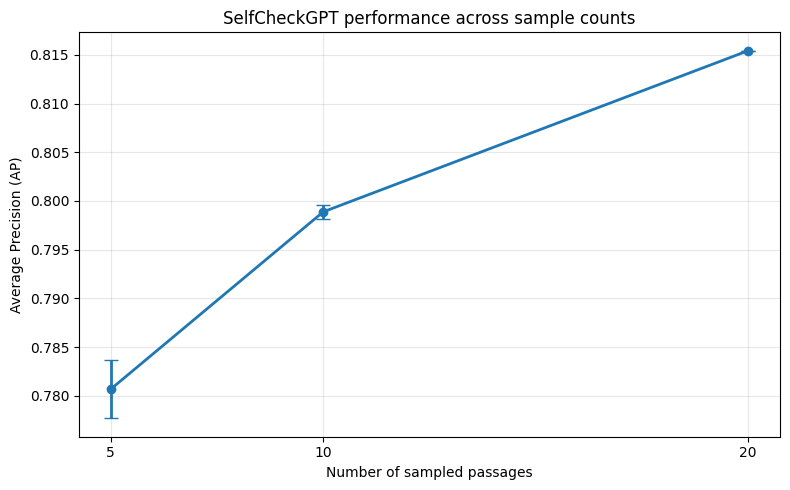

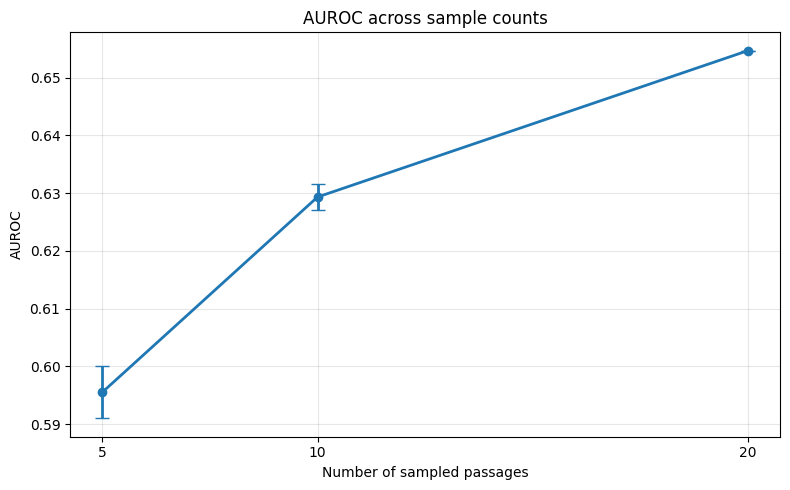

Both figures saved successfully!


In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract the actual numerical rows
plot_df = seed_summary_df.iloc[2:].copy()

plot_df["sample_count"] = pd.to_numeric(
    plot_df["Unnamed: 0"]
)

plot_df["AP_mean"] = pd.to_numeric(plot_df["AP"])
plot_df["AP_std"] = pd.to_numeric(plot_df["AP.1"])

plot_df["AUROC_mean"] = pd.to_numeric(plot_df["AUROC"])
plot_df["AUROC_std"] = pd.to_numeric(plot_df["AUROC.1"])

# Create two separate figures
plt.figure(figsize=(8, 5))

plt.errorbar(
    plot_df["sample_count"],
    plot_df["AP_mean"],
    yerr=plot_df["AP_std"],
    marker="o",
    capsize=5,
    linewidth=2
)

plt.xticks([5, 10, 20])
plt.xlabel("Number of sampled passages")
plt.ylabel("Average Precision (AP)")
plt.title("SelfCheckGPT performance across sample counts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/content/figure_ap_vs_sample_count.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


plt.figure(figsize=(8, 5))

plt.errorbar(
    plot_df["sample_count"],
    plot_df["AUROC_mean"],
    yerr=plot_df["AUROC_std"],
    marker="o",
    capsize=5,
    linewidth=2
)

plt.xticks([5, 10, 20])
plt.xlabel("Number of sampled passages")
plt.ylabel("AUROC")
plt.title("AUROC across sample counts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/content/figure_auroc_vs_sample_count.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Both figures saved successfully!")

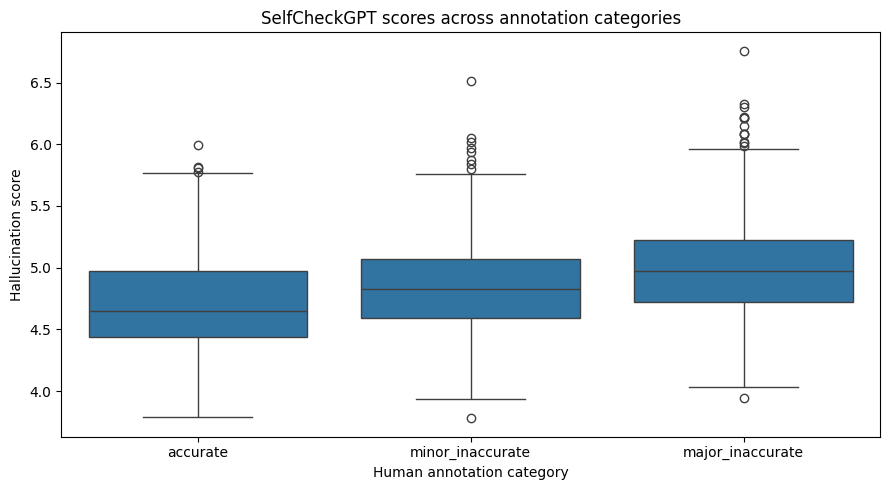

Category distribution figure saved!


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use results from all 20 sampled passages
error_df = final_results[
    final_results["sample_count"] == 20
].copy()

# Order categories logically
category_order = [
    "accurate",
    "minor_inaccurate",
    "major_inaccurate"
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=error_df,
    x="human_label",
    y="hallucination_score",
    order=category_order
)

plt.xlabel("Human annotation category")
plt.ylabel("Hallucination score")
plt.title("SelfCheckGPT scores across annotation categories")
plt.tight_layout()

plt.savefig(
    "/content/figure_score_distribution_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Category distribution figure saved!")

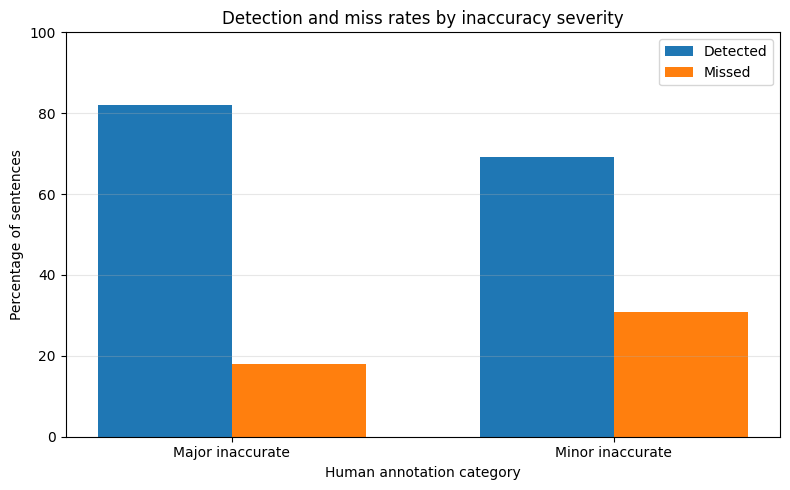

Detection versus miss-rate figure saved!


In [15]:
import matplotlib.pyplot as plt
import numpy as np

categories = ["Major inaccurate", "Minor inaccurate"]

detection_rates = [82.13, 69.26]
miss_rates = [17.87, 30.74]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    detection_rates,
    width,
    label="Detected"
)

plt.bar(
    x + width/2,
    miss_rates,
    width,
    label="Missed"
)

plt.xticks(x, categories)
plt.ylabel("Percentage of sentences")
plt.xlabel("Human annotation category")
plt.title("Detection and miss rates by inaccuracy severity")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/content/figure_detection_vs_miss_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Detection versus miss-rate figure saved!")

In [16]:
import os
import zipfile

figure_files = [
    "figure_ap_vs_sample_count.png",
    "figure_auroc_vs_sample_count.png",
    "figure_score_distribution_by_category.png",
    "figure_detection_vs_miss_rate.png"
]

zip_path = "/content/selfcheck_research_figures.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for filename in figure_files:
        filepath = "/content/" + filename

        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print("Added:", filename)
        else:
            print("Missing:", filename)

print("\nZIP created:", os.path.exists(zip_path))

Added: figure_ap_vs_sample_count.png
Added: figure_auroc_vs_sample_count.png
Added: figure_score_distribution_by_category.png
Added: figure_detection_vs_miss_rate.png

ZIP created: True


In [17]:
print("BOOTSTRAP RESULTS")
print("Shape:", bootstrap_df.shape)
print("Columns:", bootstrap_df.columns.tolist())
display(bootstrap_df)

print("\nCONFIDENCE INTERVAL RESULTS")
print("Shape:", ci_results.shape)
print("Columns:", ci_results.columns.tolist())
display(ci_results)

print("\nSEED-LEVEL RESULTS")
display(seed_metrics_df)

BOOTSTRAP RESULTS
Shape: (1000, 8)
Columns: ['AP_5', 'AP_10', 'AP_20', 'AUROC_5', 'AUROC_10', 'AUROC_20', 'AP_difference_20_5', 'AUROC_difference_20_5']


,AP_5,AP_10,AP_20,AUROC_5,AUROC_10,AUROC_20,AP_difference_20_5,AUROC_difference_20_5
0,0.768945,0.789444,0.805443,0.610812,0.650007,0.675999,0.036497,0.065187
1,0.783739,0.806223,0.820198,0.581532,0.625545,0.649683,0.036459,0.068151
2,0.763976,0.787597,0.804033,0.578765,0.617045,0.640790,0.040057,0.062025
3,0.794848,0.817137,0.829780,0.608938,0.652234,0.680557,0.034932,0.071619
4,0.763420,0.791524,0.808600,0.580109,0.629766,0.660100,0.045180,0.079991
...,...,...,...,...,...,...,...,...
995,0.789799,0.809377,0.822545,0.571554,0.616349,0.640265,0.032746,0.068711
996,0.787915,0.809347,0.827552,0.616493,0.651918,0.678606,0.039637,0.062113
997,0.801919,0.823252,0.838754,0.618479,0.658091,0.682953,0.036835,0.064474
998,0.785873,0.806041,0.824911,0.604850,0.644565,0.672782,0.039038,0.067932



CONFIDENCE INTERVAL RESULTS
Shape: (8, 4)
Columns: ['Metric', 'Bootstrap mean', '95% CI lower', '95% CI upper']


,Metric,Bootstrap mean,95% CI lower,95% CI upper
0,AP_5,0.777208,0.739070,0.814784
1,AP_10,0.800096,0.763321,0.835062
2,AP_20,0.815437,0.780104,0.849039
3,AUROC_5,0.589080,0.552282,0.624090
4,AUROC_10,0.629561,0.594559,0.665136
5,AUROC_20,0.654934,0.620660,0.688357
6,AP_difference_20_5,0.038229,0.028975,0.048379
7,AUROC_difference_20_5,0.065854,0.052687,0.079477



SEED-LEVEL RESULTS


,seed,sample_count,AP,AUROC
0,42,5,0.776859,0.589005
1,42,10,0.799799,0.629196
2,42,20,0.815420,0.654645
3,43,5,0.779152,0.594956
4,43,10,0.799468,0.626945
5,43,20,0.815420,0.654645
6,44,5,0.784334,0.597485
7,44,10,0.798386,0.627393
8,44,20,0.815420,0.654645
9,45,5,0.780070,0.594857


In [18]:
# Calculate bootstrap improvement statistics
ap_diff = bootstrap_df["AP_difference_20_5"]
auroc_diff = bootstrap_df["AUROC_difference_20_5"]

print("AP improvement (20 vs 5)")
print("Mean:", round(ap_diff.mean(), 5))
print("Median:", round(ap_diff.median(), 5))
print("Minimum:", round(ap_diff.min(), 5))
print("Maximum:", round(ap_diff.max(), 5))
print("Positive bootstrap differences:",
      (ap_diff > 0).sum(), "/ 1000")

print("\nAUROC improvement (20 vs 5)")
print("Mean:", round(auroc_diff.mean(), 5))
print("Median:", round(auroc_diff.median(), 5))
print("Minimum:", round(auroc_diff.min(), 5))
print("Maximum:", round(auroc_diff.max(), 5))
print("Positive bootstrap differences:",
      (auroc_diff > 0).sum(), "/ 1000")

AP improvement (20 vs 5)
Mean: 0.03823
Median: 0.03814
Minimum: 0.02355
Maximum: 0.05636
Positive bootstrap differences: 1000 / 1000

AUROC improvement (20 vs 5)
Mean: 0.06585
Median: 0.06577
Minimum: 0.04618
Maximum: 0.08584
Positive bootstrap differences: 1000 / 1000


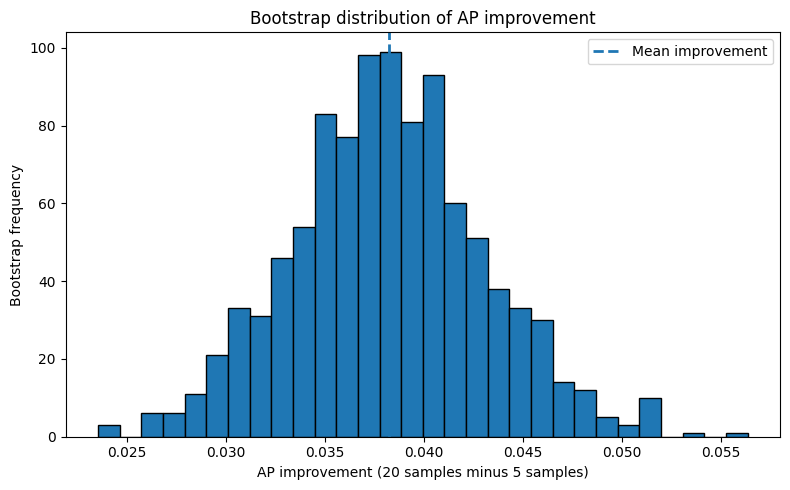

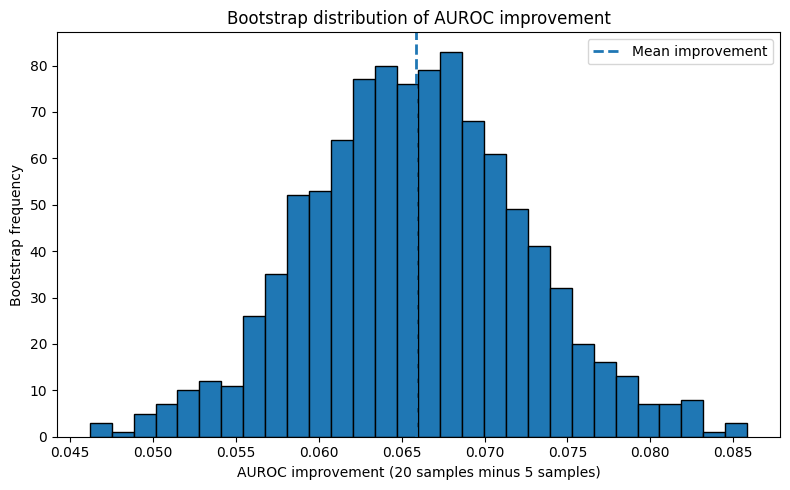

Both bootstrap improvement figures saved!


In [19]:
import matplotlib.pyplot as plt

# AP improvement distribution
plt.figure(figsize=(8, 5))

plt.hist(
    bootstrap_df["AP_difference_20_5"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    bootstrap_df["AP_difference_20_5"].mean(),
    linestyle="--",
    linewidth=2,
    label="Mean improvement"
)

plt.xlabel("AP improvement (20 samples minus 5 samples)")
plt.ylabel("Bootstrap frequency")
plt.title("Bootstrap distribution of AP improvement")
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/figure_bootstrap_ap_improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# AUROC improvement distribution
plt.figure(figsize=(8, 5))

plt.hist(
    bootstrap_df["AUROC_difference_20_5"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    bootstrap_df["AUROC_difference_20_5"].mean(),
    linestyle="--",
    linewidth=2,
    label="Mean improvement"
)

plt.xlabel("AUROC improvement (20 samples minus 5 samples)")
plt.ylabel("Bootstrap frequency")
plt.title("Bootstrap distribution of AUROC improvement")
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/figure_bootstrap_auroc_improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both bootstrap improvement figures saved!")

In [20]:
import os
import zipfile
import pandas as pd

figure_files = [
    "figure_ap_vs_sample_count.png",
    "figure_auroc_vs_sample_count.png",
    "figure_score_distribution_by_category.png",
    "figure_detection_vs_miss_rate.png",
    "figure_bootstrap_ap_improvement.png",
    "figure_bootstrap_auroc_improvement.png"
]

zip_path = "/content/selfcheck_research_figures_final.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for filename in figure_files:
        filepath = "/content/" + filename

        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print("Added:", filename)
        else:
            print("WARNING - Missing:", filename)

print("\nFinal figure archive created:", os.path.exists(zip_path))

Added: figure_ap_vs_sample_count.png
Added: figure_auroc_vs_sample_count.png
Added: figure_score_distribution_by_category.png
Added: figure_detection_vs_miss_rate.png
Added: figure_bootstrap_ap_improvement.png
Added: figure_bootstrap_auroc_improvement.png

Final figure archive created: True


In [21]:
import pandas as pd

# Prepare clean performance summary
results_summary = seed_summary_df.iloc[2:].copy()

results_summary = pd.DataFrame({
    "sample_count": pd.to_numeric(results_summary["Unnamed: 0"]),
    "AP_mean": pd.to_numeric(results_summary["AP"]),
    "AP_std": pd.to_numeric(results_summary["AP.1"]),
    "AUROC_mean": pd.to_numeric(results_summary["AUROC"]),
    "AUROC_std": pd.to_numeric(results_summary["AUROC.1"])
})

# Prepare clean confidence interval table
bootstrap_summary = ci_results.copy()

# Save both tables
results_summary.to_csv(
    "/content/selfcheck_final_performance_summary.csv",
    index=False
)

bootstrap_summary.to_csv(
    "/content/selfcheck_final_bootstrap_summary.csv",
    index=False
)

# Display results
print("FINAL PERFORMANCE SUMMARY")
display(results_summary)

print("\nBOOTSTRAP CONFIDENCE INTERVALS")
display(bootstrap_summary)

print("\nBoth files saved successfully!")

FINAL PERFORMANCE SUMMARY


,sample_count,AP_mean,AP_std,AUROC_mean,AUROC_std
2,5,0.780681,0.002999,0.595548,0.00453
3,10,0.798878,0.000740,0.629322,0.00220
4,20,0.815420,0.000000,0.654645,0.00000



BOOTSTRAP CONFIDENCE INTERVALS


,Metric,Bootstrap mean,95% CI lower,95% CI upper
0,AP_5,0.777208,0.739070,0.814784
1,AP_10,0.800096,0.763321,0.835062
2,AP_20,0.815437,0.780104,0.849039
3,AUROC_5,0.589080,0.552282,0.624090
4,AUROC_10,0.629561,0.594559,0.665136
5,AUROC_20,0.654934,0.620660,0.688357
6,AP_difference_20_5,0.038229,0.028975,0.048379
7,AUROC_difference_20_5,0.065854,0.052687,0.079477



Both files saved successfully!


In [22]:
import os

expected_files = [
    "selfcheck_results.csv",
    "selfcheck_additional_seeds.csv",
    "selfcheck_seed_metrics.csv",
    "selfcheck_seed_summary.csv",
    "selfcheck_bootstrap_results.csv",
    "selfcheck_confidence_intervals.csv",
    "selfcheck_pairwise_seed_results.csv",
    "selfcheck_pairwise_results_seed42.csv",
    "selfcheck_category_analysis.csv",
    "selfcheck_false_positives.csv",
    "selfcheck_false_negatives.csv",
    "selfcheck_category_error_analysis.csv",
    "selfcheck_threshold_analysis.csv",
    "selfcheck_final_performance_summary.csv",
    "selfcheck_final_bootstrap_summary.csv",
    "selfcheck_research_figures_final.zip"
]

print("FINAL RESEARCH FILE AUDIT\n")

missing = []

for filename in expected_files:
    exists = os.path.exists("/content/" + filename)

    print(
        ("FOUND   " if exists else "MISSING ") + filename
    )

    if not exists:
        missing.append(filename)

print("\nTotal expected files:", len(expected_files))
print("Files found:", len(expected_files) - len(missing))
print("Files missing:", len(missing))

if missing:
    print("\nMissing files:", missing)
else:
    print("\nAll expected research outputs are present!")

FINAL RESEARCH FILE AUDIT

FOUND   selfcheck_results.csv
FOUND   selfcheck_additional_seeds.csv
FOUND   selfcheck_seed_metrics.csv
FOUND   selfcheck_seed_summary.csv
FOUND   selfcheck_bootstrap_results.csv
FOUND   selfcheck_confidence_intervals.csv
FOUND   selfcheck_pairwise_seed_results.csv
FOUND   selfcheck_pairwise_results_seed42.csv
FOUND   selfcheck_category_analysis.csv
FOUND   selfcheck_false_positives.csv
FOUND   selfcheck_false_negatives.csv
FOUND   selfcheck_category_error_analysis.csv
FOUND   selfcheck_threshold_analysis.csv
FOUND   selfcheck_final_performance_summary.csv
FOUND   selfcheck_final_bootstrap_summary.csv
FOUND   selfcheck_research_figures_final.zip

Total expected files: 16
Files found: 16
Files missing: 0

All expected research outputs are present!


In [23]:
import os
import zipfile

expected_files = [
    "selfcheck_results.csv",
    "selfcheck_additional_seeds.csv",
    "selfcheck_seed_metrics.csv",
    "selfcheck_seed_summary.csv",
    "selfcheck_bootstrap_results.csv",
    "selfcheck_confidence_intervals.csv",
    "selfcheck_pairwise_seed_results.csv",
    "selfcheck_pairwise_results_seed42.csv",
    "selfcheck_category_analysis.csv",
    "selfcheck_false_positives.csv",
    "selfcheck_false_negatives.csv",
    "selfcheck_category_error_analysis.csv",
    "selfcheck_threshold_analysis.csv",
    "selfcheck_final_performance_summary.csv",
    "selfcheck_final_bootstrap_summary.csv",
    "selfcheck_research_figures_final.zip"
]

archive_path = "/content/complete_selfcheck_research_backup.zip"

with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in expected_files:
        filepath = "/content/" + filename

        if os.path.exists(filepath):
            archive.write(filepath, arcname=filename)

print("Master backup created:", os.path.exists(archive_path))
print("Files included:", len(expected_files))
print("Backup size (MB):", round(os.path.getsize(archive_path) / (1024 * 1024), 2))

Master backup created: True
Files included: 16
Backup size (MB): 1.04
